# EV Predictive Maintenance Dataset Preprocessing & Feature Engineering

This notebook performs end-to-end data preprocessing, exploratory analysis, domain feature engineering, outlier clipping, feature scaling, and chronological dataset partitioning for the **EV Predictive Maintenance Dataset (15-min Telemetry)**.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Data Ingestion & Integrity Inspection

We load `EV_Predictive_Maintenance_Dataset_15min.csv` and inspect schema, data types, missing values, and duplicate rows.


In [2]:
csv_path = '/Users/apple/Downloads/ml/EV_Predictive_Maintenance_Dataset_15min.csv'
df = pd.read_csv(csv_path)

print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Missing Values Count: {df.isnull().sum().sum()}")
print(f"Duplicate Rows Count: {df.duplicated().sum()}")

display(df.head())


Dataset Shape: 175,393 rows x 30 columns
Missing Values Count: 0
Duplicate Rows Count: 0


,Timestamp,SoC,SoH,Battery_Voltage,Battery_Current,Battery_Temperature,Charge_Cycles,Motor_Temperature,Motor_Vibration,Motor_Torque,Motor_RPM,Power_Consumption,Brake_Pad_Wear,Brake_Pressure,Reg_Brake_Efficiency,Tire_Pressure,Tire_Temperature,Suspension_Load,Ambient_Temperature,Ambient_Humidity,Load_Weight,Driving_Speed,Distance_Traveled,Idle_Time,Route_Roughness,RUL,Failure_Probability,Maintenance_Type,TTF,Component_Health_Score
0,2020-01-01 00:00:00,0.826099,0.941338,210.163881,-22.753095,27.149201,149.190930,48.496049,0.369095,113.435589,1996.008632,28.491339,0.237134,46.246011,0.810858,24.318716,26.699988,187.132154,13.213039,94.621365,741.754518,103.421162,66.232383,0.520922,0.225970,260.503381,0,1,111.116697,0.852745
1,2020-01-01 00:15:00,0.064728,0.916059,364.000102,-27.701120,53.655101,171.702388,57.829492,1.449195,105.587160,1798.361835,25.450963,0.126469,35.790875,0.889325,24.266465,27.214893,101.420835,-6.713220,41.033266,769.134035,46.041935,3.146238,0.844005,0.204350,212.813954,0,2,179.229425,0.827616
2,2020-01-01 00:30:00,0.873643,0.908020,388.855089,-36.646406,29.559090,191.617645,46.518363,1.859045,119.610302,1881.417071,22.618821,0.199936,30.896217,0.913198,33.387677,33.147433,175.720864,24.078900,34.406233,917.262931,59.588422,79.909148,0.992405,0.175125,273.394511,0,1,171.852663,0.876887
3,2020-01-01 00:45:00,0.853009,0.916476,370.570602,-37.609429,29.690283,111.881817,54.163681,0.381500,182.535625,1593.549698,20.838012,0.138880,43.541937,0.899215,32.261760,32.924688,129.309498,11.949569,44.478083,600.598736,44.222285,0.774000,0.007615,0.213264,229.508442,0,0,165.221328,0.816290
4,2020-01-01 01:00:00,0.947540,0.913206,390.011904,-14.275808,28.864338,163.774377,42.075978,0.433927,173.298044,1585.970891,23.663755,0.249649,48.761583,0.471733,33.083867,26.806491,165.171360,18.953288,42.783036,613.153029,41.374684,2.872124,0.771938,0.770257,257.302631,1,0,176.890659,0.744260


## 2. Statistical Summary & Data Sanity Checks

Inspect basic statistics of numerical signals to verify value ranges and identify potential anomalies.


In [3]:
display(df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']])


,mean,std,min,25%,50%,75%,max
SoC,0.779882,0.291660,0.000006,0.823508,0.882380,0.941148,0.999999
SoH,0.882219,0.164805,0.400001,0.911699,0.941193,0.970720,0.999999
Battery_Voltage,352.713482,55.246513,200.001095,355.989733,370.587405,385.262527,399.999314
Battery_Current,-47.892493,45.358339,-199.994036,-45.270093,-33.518350,-21.757595,-10.000173
Battery_Temperature,33.399346,8.655192,25.000010,27.948170,30.887664,33.826187,59.997570
Charge_Cycles,217.685124,164.506573,100.000809,129.489301,158.901349,188.312590,699.996920
Motor_Temperature,56.027332,15.447305,40.000182,45.872695,51.757365,57.678209,99.999997
Motor_Vibration,0.523942,0.434352,0.200000,0.288583,0.376488,0.465118,1.999954
Motor_Torque,179.786407,76.767046,100.000039,129.469691,158.810055,188.025425,399.998498
Motor_RPM,2235.503735,1188.119583,1500.005873,1646.972583,1793.947006,1941.249131,5999.999833


## 3. Datetime Parsing & Feature Engineering

1. Convert `Timestamp` to datetime and sort chronologically.
2. Extract temporal features (`Year`, `Month`, `Day`, `Hour`, `DayOfWeek`, `Is_Weekend`).
3. Apply cyclical encoding (`Sin_Hour`, `Cos_Hour`) to represent 24-hour cycles continuous across midnight.
4. Calculate domain-specific physical telemetry features:
   - `Motor_Temp_Delta`: Difference between Motor Temperature and Ambient Temperature.
   - `Battery_Temp_Delta`: Difference between Battery Temperature and Ambient Temperature.
   - `Power_Per_RPM`: Power Consumption relative to Motor RPM.


In [4]:
# Convert Timestamp to datetime and sort
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df = df.sort_values('Timestamp').reset_index(drop=True)

# Datetime decomposition
df['Year'] = df['Timestamp'].dt.year
df['Month'] = df['Timestamp'].dt.month
df['Day'] = df['Timestamp'].dt.day
df['Hour'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek
df['Is_Weekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)

# Cyclical encoding for Hour
df['Sin_Hour'] = np.sin(2 * np.pi * df['Hour'] / 24.0)
df['Cos_Hour'] = np.cos(2 * np.pi * df['Hour'] / 24.0)

# Domain feature engineering
df['Motor_Temp_Delta'] = df['Motor_Temperature'] - df['Ambient_Temperature']
df['Battery_Temp_Delta'] = df['Battery_Temperature'] - df['Ambient_Temperature']
df['Power_Per_RPM'] = df['Power_Consumption'] / (df['Motor_RPM'] + 1.0)

print(f"Features created. New shape: {df.shape}")
display(df[['Timestamp', 'Hour', 'Sin_Hour', 'Cos_Hour', 'Motor_Temp_Delta', 'Battery_Temp_Delta', 'Power_Per_RPM']].head())


Features created. New shape: (175393, 41)


,Timestamp,Hour,Sin_Hour,Cos_Hour,Motor_Temp_Delta,Battery_Temp_Delta,Power_Per_RPM
0,2020-01-01 00:00:00,0,0.000000,1.000000,35.283010,13.936162,0.014267
1,2020-01-01 00:15:00,0,0.000000,1.000000,64.542711,60.368320,0.014144
2,2020-01-01 00:30:00,0,0.000000,1.000000,22.439462,5.480190,0.012016
3,2020-01-01 00:45:00,0,0.000000,1.000000,42.214112,17.740714,0.013068
4,2020-01-01 01:00:00,1,0.258819,0.965926,23.122690,9.911050,0.014911


## 4. Outlier Detection & Capping (Winsorization)

Telemetry sensors can produce transient noise spikes. To avoid losing time-series sequence context, we cap extreme outliers outside $[Q_1 - 3 \times \text{IQR}, Q_3 + 3 \times \text{IQR}]$ rather than dropping rows.


In [5]:
target_cols = ['RUL', 'Failure_Probability', 'Maintenance_Type', 'TTF', 'Component_Health_Score']
discrete_cols = ['Timestamp', 'Year', 'Month', 'Day', 'Hour', 'DayOfWeek', 'Is_Weekend']
telemetry_cols = [c for c in df.columns if c not in target_cols + discrete_cols]

df_capped = df.copy()
capped_counts = {}

for col in telemetry_cols:
    Q1 = df_capped[col].quantile(0.25)
    Q3 = df_capped[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 3.0 * IQR
    upper_bound = Q3 + 3.0 * IQR
    
    outliers_mask = (df_capped[col] < lower_bound) | (df_capped[col] > upper_bound)
    capped_counts[col] = int(outliers_mask.sum())
    df_capped[col] = np.clip(df_capped[col], lower_bound, upper_bound)

print("Outlier Capping Summary:")
for col, count in capped_counts.items():
    if count > 0:
        print(f"  {col}: {count:,} values capped")


Outlier Capping Summary:
  SoC: 26,320 values capped
  SoH: 26,433 values capped
  Battery_Voltage: 26,034 values capped
  Battery_Current: 22,036 values capped
  Battery_Temperature: 15,113 values capped
  Charge_Cycles: 26,354 values capped
  Motor_Temperature: 9,057 values capped
  Motor_Vibration: 26,606 values capped
  Motor_Torque: 9,455 values capped
  Motor_RPM: 26,151 values capped
  Power_Consumption: 26,108 values capped
  Brake_Pad_Wear: 26,423 values capped
  Brake_Pressure: 9,283 values capped
  Reg_Brake_Efficiency: 20,044 values capped
  Tire_Pressure: 9,245 values capped
  Tire_Temperature: 9,436 values capped
  Suspension_Load: 26,525 values capped
  Ambient_Humidity: 20,979 values capped
  Load_Weight: 9,212 values capped
  Driving_Speed: 23,620 values capped
  Distance_Traveled: 26,178 values capped
  Idle_Time: 26,417 values capped
  Route_Roughness: 26,247 values capped
  Power_Per_RPM: 22,253 values capped


## 5. Categorical Encoding

Encode `Maintenance_Type` using One-Hot Encoding to generate binary indicator variables for each maintenance category (`Maintenance_Type_0`, `Maintenance_Type_1`, etc.).


In [6]:
df_capped['Maintenance_Type'] = df_capped['Maintenance_Type'].astype(int)
mtype_dummies = pd.get_dummies(df_capped['Maintenance_Type'], prefix='Maintenance_Type', dtype=int)
df_processed = pd.concat([df_capped, mtype_dummies], axis=1)

print("Categorical Encoding Completed. Dummy columns added:")
display(mtype_dummies.head())


Categorical Encoding Completed. Dummy columns added:


,Maintenance_Type_0,Maintenance_Type_1,Maintenance_Type_2,Maintenance_Type_3
0,0,1,0,0
1,0,0,1,0
2,0,1,0,0
3,1,0,0,0
4,1,0,0,0


## 6. Chronological Dataset Partitioning (Train / Validation / Test)

To prevent data leakage in time-series predictive maintenance models, we split the data chronologically:
- **Train Set**: First 80% of data (~140,314 rows)
- **Validation Set**: Next 10% of data (~17,539 rows)
- **Test Set**: Final 10% of data (~17,540 rows)


In [7]:
n_samples = len(df_processed)
train_end = int(n_samples * 0.80)
val_end = int(n_samples * 0.90)

train_df = df_processed.iloc[:train_end].copy()
val_df = df_processed.iloc[train_end:val_end].copy()
test_df = df_processed.iloc[val_end:].copy()

print(f"Train set: {len(train_df):,} rows ({train_df['Timestamp'].min()} to {train_df['Timestamp'].max()})")
print(f"Validation set: {len(val_df):,} rows ({val_df['Timestamp'].min()} to {val_df['Timestamp'].max()})")
print(f"Test set: {len(test_df):,} rows ({test_df['Timestamp'].min()} to {test_df['Timestamp'].max()})")


Train set: 140,314 rows (2020-01-01 00:00:00 to 2024-01-01 14:15:00)
Validation set: 17,539 rows (2024-01-01 14:30:00 to 2024-07-02 07:00:00)
Test set: 17,540 rows (2024-07-02 07:15:00 to 2025-01-01 00:00:00)


## 7. Feature Scaling (Standardization)

Standardize continuous input features using `StandardScaler`. **Crucial**: The scaler is fitted strictly on the **Training Set** and then applied to transform Validation and Test sets to prevent data leakage.


In [8]:
dummy_cols = list(mtype_dummies.columns)
exclude_from_scaling = ['Timestamp'] + target_cols + dummy_cols + ['Is_Weekend']
scale_features = [c for c in df_processed.columns if c not in exclude_from_scaling]

scaler = StandardScaler()

train_scaled = train_df.copy()
val_scaled = val_df.copy()
test_scaled = test_df.copy()

train_scaled[scale_features] = scaler.fit_transform(train_df[scale_features])
val_scaled[scale_features] = scaler.transform(val_df[scale_features])
test_scaled[scale_features] = scaler.transform(test_df[scale_features])

full_scaled = pd.concat([train_scaled, val_scaled, test_scaled], axis=0).reset_index(drop=True)

print(f"Feature Scaling completed for {len(scale_features)} features.")
display(train_scaled[scale_features[:5]].head())


Feature Scaling completed for 34 features.


,SoC,SoH,Battery_Voltage,Battery_Current,Battery_Temperature
0,-0.060240,0.289846,-2.257532,0.621654,-0.762970
1,-2.253078,-0.020839,0.121427,0.466824,2.396022
2,0.233011,-0.119634,0.738455,0.186916,-0.449827
3,0.105741,-0.015708,0.284540,0.156782,-0.432780
4,0.688814,-0.055903,0.767173,0.886919,-0.540104


## 8. Exporting Preprocessed Datasets

Export all preprocessed splits and full dataset to CSV files in `/Users/apple/Downloads/ml/`.


In [9]:
output_dir = '/Users/apple/Downloads/ml'

train_scaled.to_csv(os.path.join(output_dir, 'train_preprocessed.csv'), index=False)
val_scaled.to_csv(os.path.join(output_dir, 'val_preprocessed.csv'), index=False)
test_scaled.to_csv(os.path.join(output_dir, 'test_preprocessed.csv'), index=False)
full_scaled.to_csv(os.path.join(output_dir, 'full_preprocessed.csv'), index=False)

print("Exported files:")
print(" - train_preprocessed.csv:", f"{os.path.getsize(os.path.join(output_dir, 'train_preprocessed.csv')) / (1024*1024):.2f} MB")
print(" - val_preprocessed.csv:", f"{os.path.getsize(os.path.join(output_dir, 'val_preprocessed.csv')) / (1024*1024):.2f} MB")
print(" - test_preprocessed.csv:", f"{os.path.getsize(os.path.join(output_dir, 'test_preprocessed.csv')) / (1024*1024):.2f} MB")
print(" - full_preprocessed.csv:", f"{os.path.getsize(os.path.join(output_dir, 'full_preprocessed.csv')) / (1024*1024):.2f} MB")


Exported files:
 - train_preprocessed.csv: 102.13 MB
 - val_preprocessed.csv: 12.76 MB
 - test_preprocessed.csv: 12.75 MB
 - full_preprocessed.csv: 127.64 MB


## 9. Visualizations & Exploratory Analytics

We visualize feature distributions, correlations, and target variables across time.


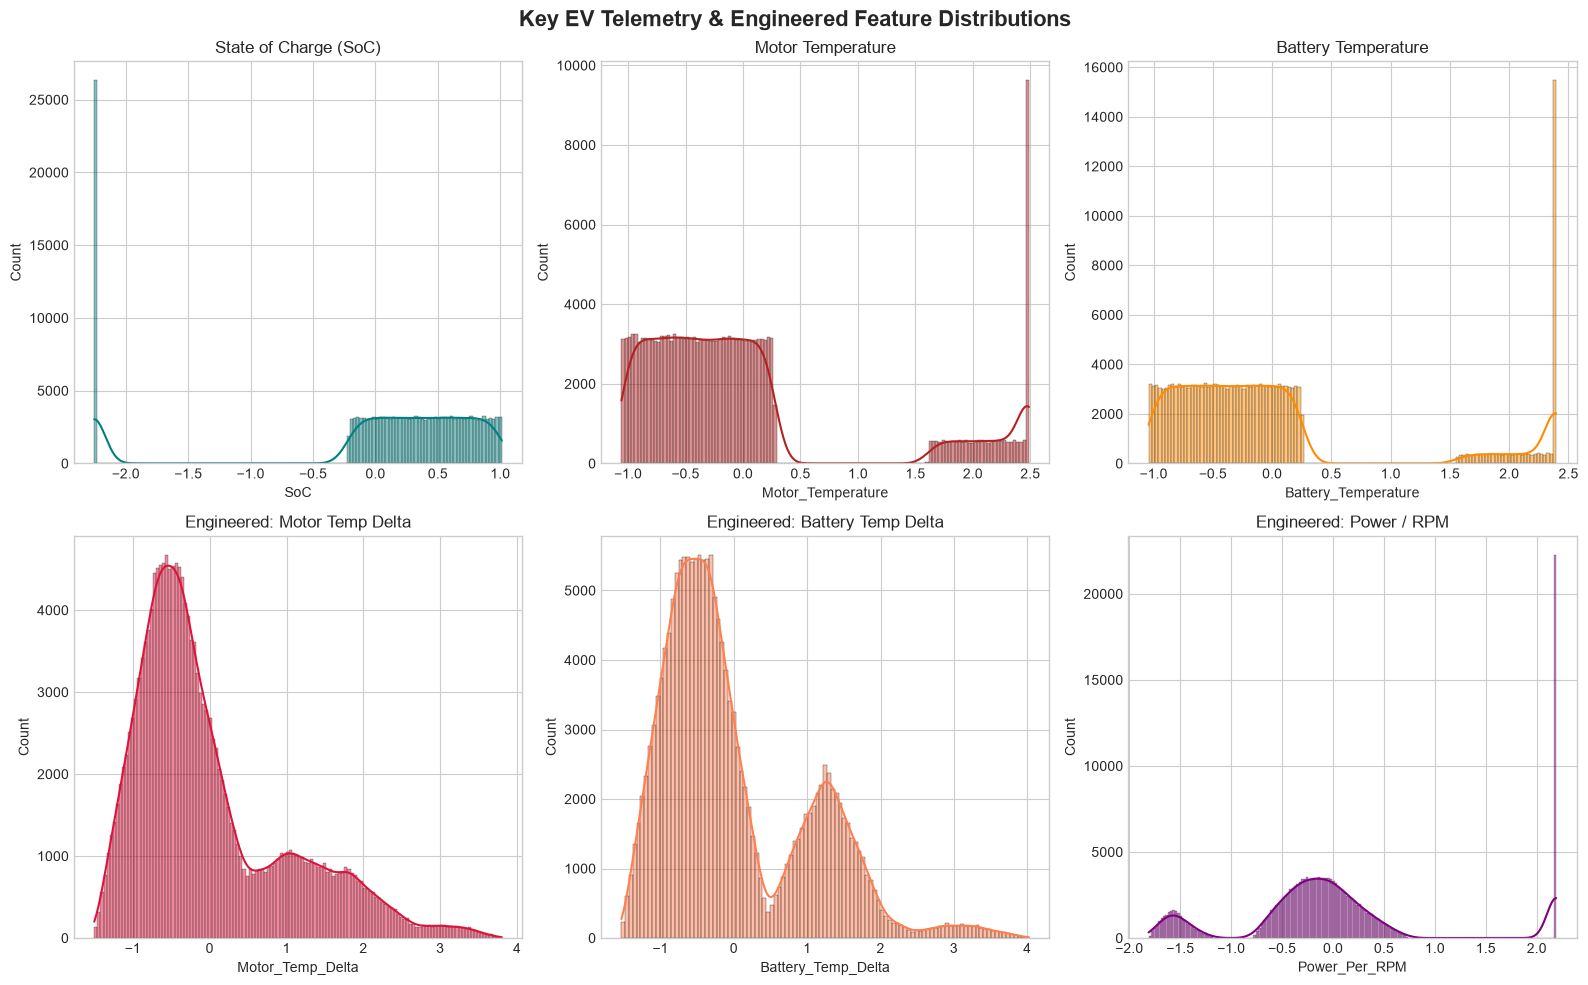

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Key EV Telemetry & Engineered Feature Distributions', fontsize=16, fontweight='bold')

sns.histplot(full_scaled['SoC'], ax=axes[0, 0], kde=True, color='teal')
axes[0, 0].set_title('State of Charge (SoC)')

sns.histplot(full_scaled['Motor_Temperature'], ax=axes[0, 1], kde=True, color='firebrick')
axes[0, 1].set_title('Motor Temperature')

sns.histplot(full_scaled['Battery_Temperature'], ax=axes[0, 2], kde=True, color='darkorange')
axes[0, 2].set_title('Battery Temperature')

sns.histplot(full_scaled['Motor_Temp_Delta'], ax=axes[1, 0], kde=True, color='crimson')
axes[1, 0].set_title('Engineered: Motor Temp Delta')

sns.histplot(full_scaled['Battery_Temp_Delta'], ax=axes[1, 1], kde=True, color='coral')
axes[1, 1].set_title('Engineered: Battery Temp Delta')

sns.histplot(full_scaled['Power_Per_RPM'], ax=axes[1, 2], kde=True, color='purple')
axes[1, 2].set_title('Engineered: Power / RPM')

plt.tight_layout()
plt.show()


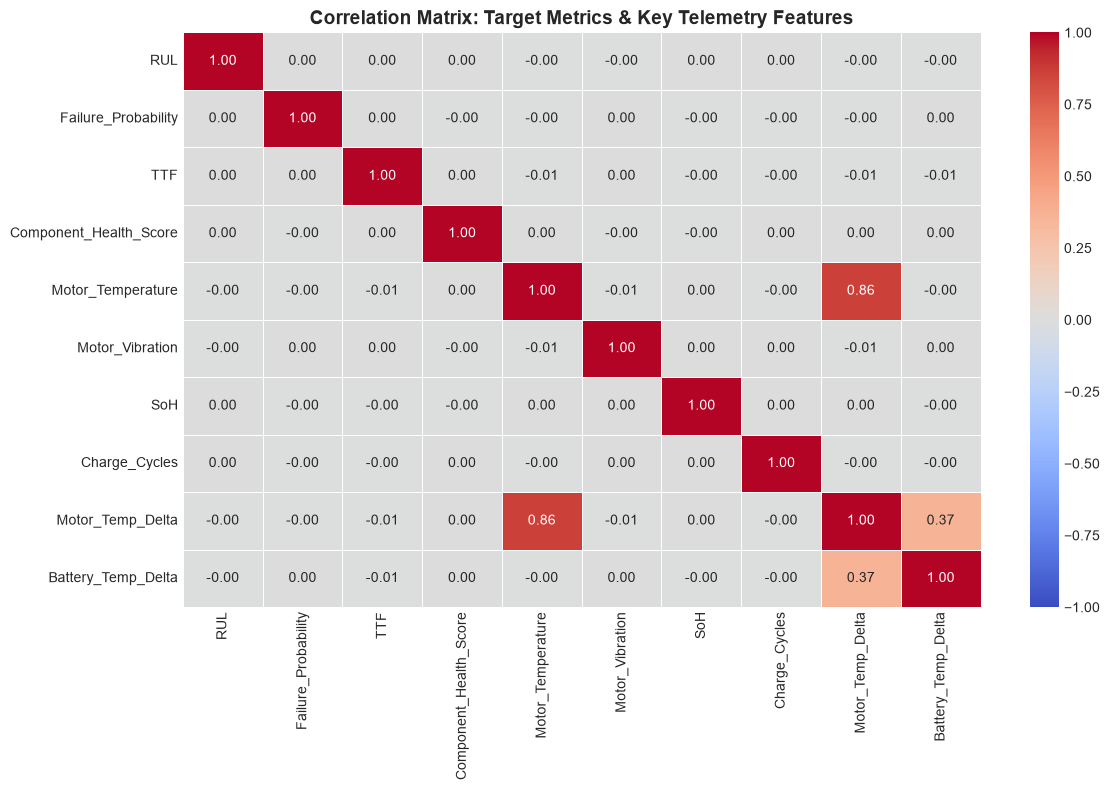

In [11]:
plt.figure(figsize=(12, 8))
corr_cols = ['RUL', 'Failure_Probability', 'TTF', 'Component_Health_Score', 
             'Motor_Temperature', 'Motor_Vibration', 'SoH', 'Charge_Cycles',
             'Motor_Temp_Delta', 'Battery_Temp_Delta']

corr_matrix = full_scaled[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix: Target Metrics & Key Telemetry Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


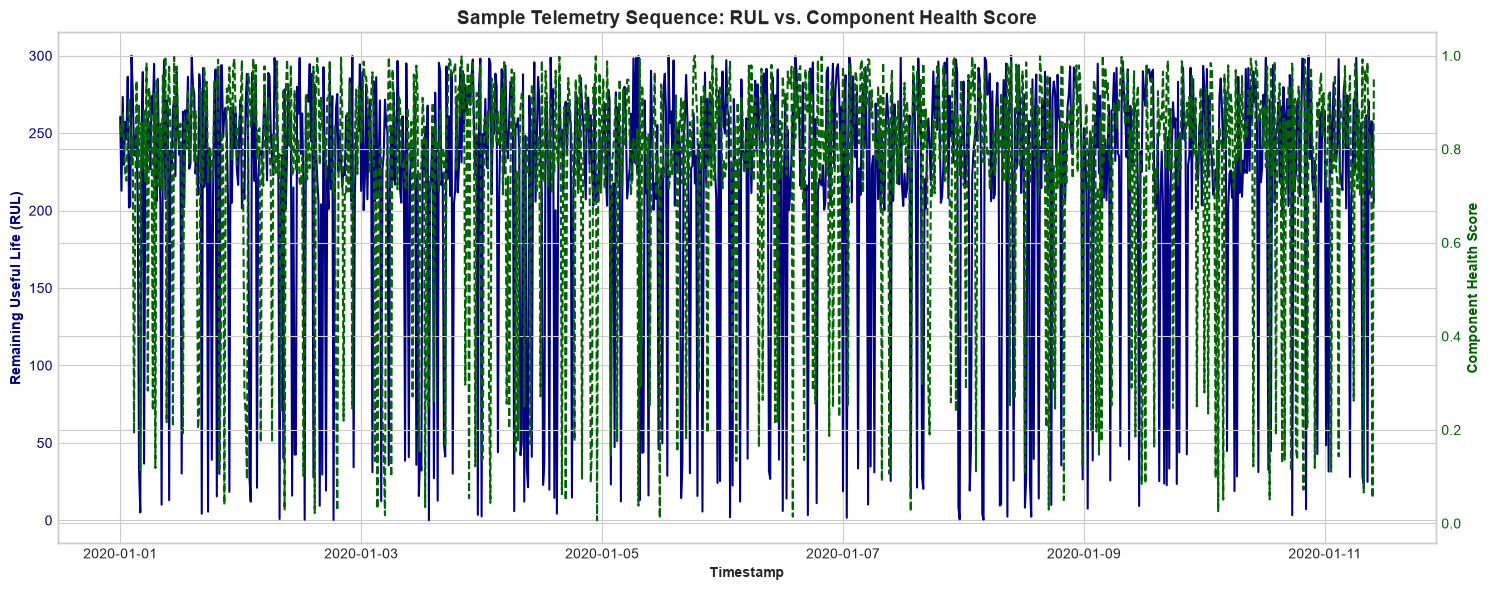

In [12]:
fig, ax1 = plt.subplots(figsize=(15, 6))

sample_sub = full_scaled.iloc[:1000]

ax1.set_xlabel('Timestamp', fontweight='bold')
ax1.set_ylabel('Remaining Useful Life (RUL)', color='navy', fontweight='bold')
ax1.plot(sample_sub['Timestamp'], sample_sub['RUL'], color='navy', label='RUL', linewidth=1.5)
ax1.tick_params(axis='y', labelcolor='navy')

ax2 = ax1.twinx()
ax2.set_ylabel('Component Health Score', color='darkgreen', fontweight='bold')
ax2.plot(sample_sub['Timestamp'], sample_sub['Component_Health_Score'], color='darkgreen', linestyle='--', label='Health Score', linewidth=1.5)
ax2.tick_params(axis='y', labelcolor='darkgreen')

plt.title('Sample Telemetry Sequence: RUL vs. Component Health Score', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()
